# Agentic Retrieval-Augmented Protein–Ligand Affinity Model (pKd)
**PDBbind v2020 · ProtBERT + MolT5 · FAISS top-3 retrieval · Agentic evidence weighting (softmax) · Pocket-aware attention fusion · MC-dropout (M=10)**

**How to use:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
The first run downloads ProtBERT/MolT5 and caches embeddings (to Google Drive if mounted), so later runs skip that step.

Pipeline (matches your workflow document):
1. Stage 0 – cache ProtBERT (protein, pocket) and MolT5 (ligand) embeddings (unique sequences only, fp16, length-sorted batches).
2. Stage 1 – train the **Interaction Query Generator**, then freeze it. A FAISS index is built **once** from the training partition.
3. Stage 2 – retrieve top-3 neighbours → 5 evidence signals → agentic scorer → softmax weights → weighted evidence → attention fusion → `Linear→GELU→Dropout→Linear` → pKd.
4. MC-dropout inference (M=10), evaluation on **pKd and z-score scales** for validation, test and external CASF-2016.

In [ ]:
#@title 0. Get the repository (Colab only; skipped if already present)
import os, subprocess
REPO = "/content/agentic-pla-reproducibility"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/RenjithaRajan/agentic-pla-reproducibility.git", REPO], check=True)
os.chdir(REPO)
print("Working directory:", os.getcwd())


In [1]:
#@title 1. Setup, configuration, Drive (optional)
!pip -q install faiss-cpu sentencepiece
import os, re, json, time, math, random, hashlib, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.stats import pearsonr, spearmanr
warnings.filterwarnings("ignore")

CFG = dict(
    seed=42,
    K=3,                      # fixed retrieval neighbourhood (workflow doc)
    max_epochs=250,           # maximum training epochs (workflow doc)
    patience=30,              # early stopping on validation RMSE
    mc_samples=10,            # MC-dropout passes (workflow doc)
    prot_model="Rostlab/prot_bert",
    mol_model="laituan245/molt5-base",
    max_prot_len=1024, max_smiles_len=256, max_pocket_len=128,
    gen_dim=256,              # interaction embedding size (used for FAISS)
    n_folds=5,                # OOF folds for the label-free 'base estimate' used in the consistency signal
    n_trials=8,               # random-search trials for stage-2 hyper-parameters (set 0 to skip)
    n_seeds=5,                # stage-2 ensemble size (set 1 for the strict single-model configuration)
    run_ablation=True,        # compare agentic weights against uniform 1/3 weights
    casf_db="train",          # retrieval DB for CASF-2016: "train" (strict) or "train+val"
    use_drive=False,          # repository version: keep everything inside the repo
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if dev.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Use Runtime > Change runtime type > T4 GPU (ProtBERT is very slow on CPU).")

OUT_DIR = "."
CACHE_DIR, RES_DIR = "cache", "results"   # cache is git-ignored; results are committed
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
print("Outputs ->", OUT_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 89.2 MB/s eta 0:00:00
GPU: Tesla T4
Mounted at /content/drive
Outputs -> /content/drive/MyDrive/agentic_pla


In [2]:
#@title 2. Load data (downloads from your Drive links; falls back to manual upload)
DATA_DIR = "data"
for fn in ["processed_pdbbind.csv", "processed_casf2016.csv"]:
    if not os.path.exists(f"{DATA_DIR}/{fn}"):
        raise FileNotFoundError(f"Missing {DATA_DIR}/{fn}. See data/README.md for how to obtain it.")

pdb = pd.read_csv(f"{DATA_DIR}/processed_pdbbind.csv"); pdb["part"] = pdb["split"]
casf = pd.read_csv(f"{DATA_DIR}/processed_casf2016.csv"); casf["part"] = "casf"
df = pd.concat([pdb, casf], ignore_index=True)
N = len(df)
rows = {p: np.where(df.part.values == p)[0] for p in ["train", "val", "test", "casf"]}
print({k: len(v) for k, v in rows.items()})
print("PDB-id overlap PDBbind/CASF:", len(set(pdb.pdb_id) & set(casf.pdb_id)), "(must be 0)")

Y = df.binding_affinity.values.astype(np.float32)
MU, SD = float(Y[rows["train"]].mean()), float(Y[rows["train"]].std())   # z-score stats from TRAIN only
Zn = ((Y - MU) / SD).astype(np.float32)
print(f"train pKd mean={MU:.3f} sd={SD:.3f}")

AA3 = dict(ALA="A",ARG="R",ASN="N",ASP="D",CYS="C",GLN="Q",GLU="E",GLY="G",HIS="H",ILE="I",LEU="L",LYS="K",MET="M",
           PHE="F",PRO="P",SER="S",THR="T",TRP="W",TYR="Y",VAL="V",SEC="U",PYL="O",MSE="M",HID="H",HIE="H",HIP="H",CYX="C")
def pocket_to_seq(s):
    return "".join(AA3.get(t.split(":")[1], "X") for t in str(s).split(";") if t.count(":") >= 2)
df["pocket_seq"] = df.pocket_residues.map(pocket_to_seq)
COMP = np.stack([np.asarray(json.loads(s), dtype=np.float32) for s in df.pocket_composition]).astype(np.float32)
print("pocket comp dim:", COMP.shape, "| example pocket:", df.pocket_seq.iloc[0])

{'train': 4690, 'val': 1005, 'test': 1005, 'casf': 107}
PDB-id overlap PDBbind/CASF: 0 (must be 0)
train pKd mean=5.850 sd=1.722
pocket comp dim: (6807, 20) | example pocket: ILVYLAMVVFSLLLF


In [3]:
#@title 3. Metrics (pKd scale AND z-score scale)
def concordance_index(y, p):
    dy = y[:, None] - y[None, :]; dp = p[:, None] - p[None, :]
    m = dy > 0
    return float(((dp[m] > 0).sum() + 0.5 * (dp[m] == 0).sum()) / max(m.sum(), 1))

def _metrics(y, p):
    y = np.asarray(y, np.float64); p = np.asarray(p, np.float64); n = len(y)
    err = p - y
    mse = float(np.mean(err ** 2))
    sst = float(np.sum((y - y.mean()) ** 2))
    a, b = np.polyfit(p, y, 1)                                   # CASF-style SD: residual SD of linear fit y ~ a*p+b
    sd = float(np.sqrt(np.sum((y - (a * p + b)) ** 2) / (n - 1)))
    return dict(MAE=float(np.mean(np.abs(err))), MSE=mse, RMSE=math.sqrt(mse),
                Pearson=float(pearsonr(p, y)[0]), R2=float(1 - np.sum(err ** 2) / sst),
                SD=sd, CI=concordance_index(y, p))

def metrics_both(y_pkd, p_pkd):
    """Returns a 2-row DataFrame: metrics on the pKd scale and on the z-score scale (train mean/std)."""
    zy, zp = (np.asarray(y_pkd) - MU) / SD, (np.asarray(p_pkd) - MU) / SD
    return pd.DataFrame({"pKd": _metrics(y_pkd, p_pkd), "z-score": _metrics(zy, zp)}).T

# quick self-test
_t = np.random.RandomState(0).randn(200) * 1.7 + 5.8
print(metrics_both(_t, _t + np.random.RandomState(1).randn(200) * 0.5).round(3))

           MAE    MSE   RMSE  Pearson    R2     SD     CI
pKd      0.362  0.210  0.458    0.968  0.93  0.438  0.925
z-score  0.210  0.071  0.266    0.968  0.93  0.254  0.925


In [4]:
#@title 4. Stage 0 - cache ProtBERT / MolT5 embeddings (unique sequences, fp16, length-sorted)
def _hash():
    h = hashlib.md5()
    for col in ["protein_seq", "ligand_smiles", "pocket_seq"]: h.update("|".join(df[col].astype(str)).encode())
    h.update((CFG["prot_model"] + CFG["mol_model"] + str(CFG["max_prot_len"]) + str(CFG["max_smiles_len"])).encode())
    return h.hexdigest()[:12]

@torch.no_grad()
def encode_texts(texts, tok, model, prep, max_len, budget):
    """Mean-pooled last hidden state (special tokens excluded). Unique texts only; batches built by token budget."""
    uniq = sorted(set(texts), key=len); emb = {}
    special = torch.tensor(tok.all_special_ids, device=dev)
    i = 0
    while i < len(uniq):
        j = i + 1
        while j < len(uniq) and (j - i + 1) * min(len(uniq[j]), max_len) <= budget: j += 1
        enc = tok([prep(t) for t in uniq[i:j]], return_tensors="pt", padding=True, truncation=True,
                  max_length=max_len + 2).to(dev)
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state.float()
        m = (enc["attention_mask"].bool() & ~torch.isin(enc["input_ids"], special)).unsqueeze(-1).float()
        v = ((out * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        for t, vec in zip(uniq[i:j], v): emb[t] = vec
        i = j
    return np.stack([emb[t] for t in texts]).astype(np.float32)

_prot_prep = lambda s: " ".join(re.sub(r"[UZOB]", "X", s[:CFG["max_prot_len"]]))
_ENC = {}
def get_prot_encoder():
    if "prot" not in _ENC:
        from transformers import BertModel, BertTokenizer
        tok = BertTokenizer.from_pretrained(CFG["prot_model"], do_lower_case=False)
        m = BertModel.from_pretrained(CFG["prot_model"]).to(dev).eval()
        if dev.type == "cuda": m = m.half()
        _ENC["prot"] = (tok, m)
    return _ENC["prot"]
def get_mol_encoder():
    if "mol" not in _ENC:
        from transformers import AutoTokenizer, T5EncoderModel
        tok = AutoTokenizer.from_pretrained(CFG["mol_model"])
        m = T5EncoderModel.from_pretrained(CFG["mol_model"]).to(dev).eval()   # fp32: T5 can overflow in fp16
        _ENC["mol"] = (tok, m)
    return _ENC["mol"]
def free_encoders():
    _ENC.clear(); import gc; gc.collect(); torch.cuda.empty_cache()

def embed_proteins(seqs):
    tok, m = get_prot_encoder(); return encode_texts(list(seqs), tok, m, _prot_prep, CFG["max_prot_len"], 16000)
def embed_pockets(seqs):
    tok, m = get_prot_encoder(); return encode_texts(list(seqs), tok, m, _prot_prep, CFG["max_pocket_len"], 16000)
def embed_smiles(smis):
    tok, m = get_mol_encoder(); return encode_texts(list(smis), tok, m, lambda s: s, CFG["max_smiles_len"], 6000)

cache_f = f"{CACHE_DIR}/emb_{_hash()}.npz"
if os.path.exists(cache_f):
    z = np.load(cache_f); RAW_P, RAW_K, RAW_L = z["P"], z["K"], z["L"]; print("Loaded cached embeddings:", cache_f)
else:
    t0 = time.time()
    RAW_P = embed_proteins(df.protein_seq.values);  print(f"ProtBERT proteins {RAW_P.shape}  {time.time()-t0:.0f}s")
    RAW_K = embed_pockets(df.pocket_seq.values);    print(f"ProtBERT pockets  {RAW_K.shape}  {time.time()-t0:.0f}s")
    RAW_L = embed_smiles(df.ligand_smiles.values);  print(f"MolT5 ligands     {RAW_L.shape}  {time.time()-t0:.0f}s")
    np.savez_compressed(cache_f, P=RAW_P, K=RAW_K, L=RAW_L); print("Saved:", cache_f)
free_encoders()
assert not np.isnan(RAW_P).any() and not np.isnan(RAW_L).any() and not np.isnan(RAW_K).any()

Loaded cached embeddings: /content/drive/MyDrive/agentic_pla/cache/emb_897e80c8cf10.npz


In [5]:
#@title 5. Build GPU tensors (standardised with TRAIN statistics only)
tr_i = rows["train"]
def _stats(A): return A[tr_i].mean(0, keepdims=True), A[tr_i].std(0, keepdims=True) + 1e-6
NORM = {}
NORM["PM"], NORM["PS"] = _stats(RAW_P); NORM["KM"], NORM["KS"] = _stats(RAW_K); NORM["LM"], NORM["LS"] = _stats(RAW_L)
NORM["CM"] = COMP[tr_i].mean(0, keepdims=True)

def tt(a): return torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32, device=dev)
def pocket_rep(Kraw, comp):
    """Pocket representation = [L2(ProtBERT pocket emb), L2(composition-centered)] / sqrt(2), unit norm."""
    k = F.normalize(tt((Kraw - NORM["KM"]) / NORM["KS"]), dim=-1)
    c = F.normalize(tt(comp - NORM["CM"]), dim=-1)
    return F.normalize(torch.cat([k, c], -1), dim=-1)

T = {}
T["P"] = tt((RAW_P - NORM["PM"]) / NORM["PS"]); T["Pn"] = F.normalize(T["P"], dim=-1)
T["L"] = tt((RAW_L - NORM["LM"]) / NORM["LS"]); T["Ln"] = F.normalize(T["L"], dim=-1)
T["R"] = pocket_rep(RAW_K, COMP)
T["Z"] = tt(Zn)
print({k: tuple(v.shape) for k, v in T.items()})

{'P': (6807, 1024), 'Pn': (6807, 1024), 'L': (6807, 768), 'Ln': (6807, 768), 'R': (6807, 1044), 'Z': (6807,)}


In [6]:
#@title 6. Stage 1 - Interaction Query Generator (trained once, then frozen) + label-free OOF base estimate
from sklearn.model_selection import KFold

class InteractionGenerator(nn.Module):
    """protein emb + ligand emb -> interaction embedding (unit-norm, used for FAISS). Aux head regresses z-pKd."""
    def __init__(s, dp, dl, d=256, h=512, p=0.2):
        super().__init__()
        s.pp = nn.Sequential(nn.Dropout(0.1), nn.LayerNorm(dp), nn.Linear(dp, h), nn.GELU())
        s.lp = nn.Sequential(nn.Dropout(0.1), nn.LayerNorm(dl), nn.Linear(dl, h), nn.GELU())
        s.mix = nn.Sequential(nn.Linear(3 * h, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, d))
        s.head = nn.Sequential(nn.GELU(), nn.Dropout(p), nn.Linear(d, 1))
    def forward(s, P, L):
        a, b = s.pp(P), s.lp(L)
        e = s.mix(torch.cat([a, b, a * b], -1))
        return s.head(e).squeeze(-1), F.normalize(e, dim=-1)

def train_gen(tr, va, seed, max_epochs=None, patience=None, lr=1e-3, wd=1e-2, bs=256):
    max_epochs = max_epochs or CFG["max_epochs"]; patience = patience or CFG["patience"]
    set_seed(seed)
    m = InteractionGenerator(T["P"].shape[1], T["L"].shape[1], CFG["gen_dim"]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    trt, vat = torch.as_tensor(tr, device=dev), torch.as_tensor(va, device=dev)
    best, best_sd, bad = 1e9, None, 0
    for ep in range(max_epochs):
        m.train(); perm = trt[torch.randperm(len(trt), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.mse_loss(m(T["P"][b], T["L"][b])[0], T["Z"][b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad(): v = F.mse_loss(m(T["P"][vat], T["L"][vat])[0], T["Z"][vat]).sqrt().item()
        sch.step(v)
        if v < best - 1e-4: best, bad, best_sd = v, 0, {k: x.clone() for k, x in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(best_sd); return m.eval(), best

@torch.no_grad()
def gen_forward(m, idx):
    idx = torch.as_tensor(idx, device=dev); outs, embs = [], []
    for i in range(0, len(idx), 2048):
        b = idx[i:i + 2048]; p, e = m(T["P"][b], T["L"][b]); outs.append(p); embs.append(e)
    return torch.cat(outs), torch.cat(embs)

t0 = time.time()
FULL_GEN, v = train_gen(rows["train"], rows["val"], CFG["seed"])
print(f"Interaction generator trained: val RMSE(z)={v:.4f}  ({time.time()-t0:.0f}s)")
_, Hall = gen_forward(FULL_GEN, np.arange(N)); T["H"] = Hall                     # frozen interaction embeddings
GEN_Z = gen_forward(FULL_GEN, np.arange(N))[0]                                   # stage-1-only predictions (baseline)

# Label-free base estimate for the 'affinity consistency' signal: out-of-fold for train rows (no self-leak)
ZBASE = torch.zeros(N, device=dev); FOLD_MODELS = []
kf = KFold(CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
for k, (a, b) in enumerate(kf.split(rows["train"])):
    mk, _ = train_gen(rows["train"][a], rows["train"][b], CFG["seed"] + 1 + k, patience=20)
    FOLD_MODELS.append(mk); ZBASE[torch.as_tensor(rows["train"][b], device=dev)] = gen_forward(mk, rows["train"][b])[0]
other = np.concatenate([rows["val"], rows["test"], rows["casf"]])
ZBASE[torch.as_tensor(other, device=dev)] = torch.stack([gen_forward(mk, other)[0] for mk in FOLD_MODELS]).mean(0)
print(f"Stage 1 + OOF done ({time.time()-t0:.0f}s)")

Interaction generator trained: val RMSE(z)=0.7812  (19s)
Stage 1 + OOF done (42s)


In [7]:
#@title 7. FAISS retrieval (built ONCE from the training partition) + 5 evidence signals
class TorchIndex:                                   # fallback if faiss is unavailable
    def __init__(s, X): s.X = torch.as_tensor(X, device=dev)
    def search(s, q, k):
        D, I = (torch.as_tensor(q, device=dev) @ s.X.T).topk(k, dim=1); return D.cpu().numpy(), I.cpu().numpy()
def make_index(Hdb):
    Hdb = np.ascontiguousarray(Hdb.astype(np.float32))
    try:
        import faiss; ix = faiss.IndexFlatIP(Hdb.shape[1]); ix.add(Hdb); return ix      # exact inner product = cosine
    except Exception as e:
        print("faiss unavailable, using torch fallback:", e); return TorchIndex(Hdb)

@torch.no_grad()
def build_split(T, q_rows, db_rows, index, zbase, exclude_self):
    """Retrieve top-K neighbours and compute X_i=[interaction, protein, ligand, pocket, affinity-consistency].
    The TRUE affinity of the query is never used. For training queries the query itself is removed from the DB hits."""
    K = CFG["K"]; q_rows = np.asarray(q_rows); db_rows = np.asarray(db_rows)
    qh = T["H"][torch.as_tensor(q_rows, device=dev)].cpu().numpy().astype(np.float32)
    D, I = index.search(qh, K + 1 if exclude_self else K)
    if exclude_self:
        pos = np.full(T["Z"].shape[0], -1); pos[db_rows] = np.arange(len(db_rows)); sp = pos[q_rows]
        I2 = np.zeros((len(q_rows), K), np.int64); D2 = np.zeros((len(q_rows), K), np.float32)
        for r in range(len(q_rows)):
            keep = I[r] != sp[r]; I2[r] = I[r][keep][:K]; D2[r] = D[r][keep][:K]
        I, D = I2, D2
    qi = torch.as_tensor(q_rows, device=dev); ni = torch.as_tensor(db_rows[I], device=dev)
    inter = torch.as_tensor(D, device=dev, dtype=torch.float32)
    prot = (T["Pn"][qi].unsqueeze(1) * T["Pn"][ni]).sum(-1)
    lig = (T["Ln"][qi].unsqueeze(1) * T["Ln"][ni]).sum(-1)
    pock = (T["R"][qi].unsqueeze(1) * T["R"][ni]).sum(-1)
    zn = T["Z"][ni]; zb = zbase[qi]
    others = (zn.sum(1, keepdim=True) - zn) / (K - 1)
    cons = -0.5 * ((zn - zb.unsqueeze(1)).abs() + (zn - others).abs())              # label-free consistency
    return dict(q=qi, nbr=ni, X=torch.stack([inter, prot, lig, pock, cons], -1))

t0 = time.time()
DB_TRAIN = rows["train"]
INDEX_TRAIN = make_index(T["H"][torch.as_tensor(DB_TRAIN, device=dev)].cpu().numpy())
SPL = {"train": build_split(T, rows["train"], DB_TRAIN, INDEX_TRAIN, ZBASE, exclude_self=True),
       "val":   build_split(T, rows["val"],   DB_TRAIN, INDEX_TRAIN, ZBASE, False),
       "test":  build_split(T, rows["test"],  DB_TRAIN, INDEX_TRAIN, ZBASE, False)}
if CFG["casf_db"] == "train+val":
    DB_CASF = np.concatenate([rows["train"], rows["val"]])
    SPL["casf"] = build_split(T, rows["casf"], DB_CASF, make_index(T["H"][torch.as_tensor(DB_CASF, device=dev)].cpu().numpy()), ZBASE, False)
else:
    SPL["casf"] = build_split(T, rows["casf"], DB_TRAIN, INDEX_TRAIN, ZBASE, False)      # CASF never enters the DB

SIG_MU = SPL["train"]["X"].reshape(-1, 5).mean(0); SIG_SD = SPL["train"]["X"].reshape(-1, 5).std(0) + 1e-6
for s in SPL.values(): s["X"] = (s["X"] - SIG_MU) / SIG_SD
print(f"Retrieval done ({time.time()-t0:.1f}s) | mean raw signals (train):", [round(float(x), 3) for x in SIG_MU])

Retrieval done (0.6s) | mean raw signals (train): [0.921, 0.705, 0.684, 0.42, -0.453]


In [8]:
#@title 8. Stage 2 model - agentic evidence scoring, softmax weighting, attention fusion, MC-dropout head
class AgenticFusion(nn.Module):
    def __init__(s, dh, dp, dl, dk, d=128, heads=4, p=0.2, p_in=0.1, uniform=False):
        super().__init__()
        s.uniform = uniform
        proj = lambda i: nn.Sequential(nn.LayerNorm(i), nn.Linear(i, d))
        s.eh, s.ep, s.el, s.ek = proj(dh), proj(dp), proj(dl), proj(dk)           # projected retrieved representations
        s.ey, s.ex = nn.Linear(1, d), nn.Linear(5, d)                              # retrieved affinity + evidence signals
        s.ev_mix = nn.Linear(6 * d, d); s.in_drop = nn.Dropout(p_in)
        s.scorer = nn.Sequential(nn.Linear(5, 32), nn.GELU(), nn.Linear(32, 1))   # agentic evidence scorer: X_i -> S_i
        s.q_proj = nn.Linear(dh + dk, d)                                           # query interaction + query pocket
        s.attn = nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True)
        s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.ffn = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        s.head_drop = nn.Dropout(p)                                                # <- MC dropout layer
        s.head = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), s.head_drop, nn.Linear(d, 1))
        s.beta = nn.Parameter(torch.tensor(0.5))                                   # learnable skip from weighted retrieved affinity
    def encode(s, b):
        X = b["X"]; K = X.shape[1]
        sc = s.scorer(X).squeeze(-1)                                               # S_i
        alpha = torch.full_like(sc, 1.0 / K) if s.uniform else torch.softmax(sc, dim=-1)   # alpha_i = softmax(S_i)
        E = F.gelu(s.ev_mix(torch.cat([s.eh(b["hn"]), s.ep(b["pn"]), s.el(b["ln"]), s.ek(b["rn"]),
                                       s.ey(b["zn"].unsqueeze(-1)), s.ex(X)], -1)))
        Er = (alpha.unsqueeze(-1) * s.in_drop(E)).sum(1)                           # E_r = sum_i alpha_i E_i
        Q = F.gelu(s.q_proj(torch.cat([b["hq"], b["rq"]], -1)))
        tok = torch.stack([Q, Er], 1); a, _ = s.attn(tok, tok, tok, need_weights=False)
        x = s.n1(tok + a); x = s.n2(x + s.ffn(x))
        return x.flatten(1), (alpha * b["zn"]).sum(1), alpha
    def head_out(s, u, base): return s.head(u).squeeze(-1) + s.beta * base

def gather(T, sp, b):
    q, nb = sp["q"][b], sp["nbr"][b]
    return dict(hq=T["H"][q], rq=T["R"][q], hn=T["H"][nb], pn=T["P"][nb], ln=T["L"][nb], rn=T["R"][nb],
                zn=T["Z"][nb], X=sp["X"][b])

@torch.no_grad()
def predict_det(model, sp, T_=None, bs=1024):
    T_ = T_ or T; model.eval(); out = []
    for i in range(0, len(sp["q"]), bs):
        b = torch.arange(i, min(i + bs, len(sp["q"])), device=dev); u, base, _ = model.encode(gather(T_, sp, b)); out.append(model.head_out(u, base))
    return torch.cat(out)

@torch.no_grad()
def predict_mc(model, sp, M, T_=None, bs=1024):
    """MC dropout: only the prediction-head dropout is activated; M stochastic passes of the same input."""
    T_ = T_ or T; model.eval(); model.head_drop.train(); P, A = [], []
    for i in range(0, len(sp["q"]), bs):
        b = torch.arange(i, min(i + bs, len(sp["q"])), device=dev); u, base, al = model.encode(gather(T_, sp, b))
        P.append(torch.stack([model.head_out(u, base) for _ in range(M)])); A.append(al)
    model.head_drop.eval(); return torch.cat(P, 1).cpu().numpy(), torch.cat(A).cpu().numpy()

def make_model(hp, uniform=False):
    return AgenticFusion(T["H"].shape[1], T["P"].shape[1], T["L"].shape[1], T["R"].shape[1], d=hp["d"], p=hp["p"],
                         p_in=hp["p_in"], uniform=uniform).to(dev)

def fit_stage2(hp, seed, uniform=False, verbose=False):
    set_seed(seed); model = make_model(hp, uniform)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    tr, va = SPL["train"], SPL["val"]; n = len(tr["q"]); yv = T["Z"][va["q"]]
    best, best_sd, bad = 1e9, None, 0
    for ep in range(CFG["max_epochs"]):
        model.train(); perm = torch.randperm(n, device=dev)
        for i in range(0, n, hp["bs"]):
            b = perm[i:i + hp["bs"]]; u, base, _ = model.encode(gather(T, tr, b))
            loss = F.mse_loss(model.head_out(u, base), T["Z"][tr["q"][b]])
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        v = F.mse_loss(predict_det(model, va), yv).sqrt().item(); sch.step(v)
        if verbose and ep % 10 == 0: print(f"ep {ep:3d} val RMSE(z) {v:.4f}")
        if v < best - 1e-4: best, bad, best_sd = v, 0, {k: x.clone() for k, x in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]: break
    model.load_state_dict(best_sd); return model.eval(), best, ep + 1
print("Stage-2 model defined. Parameters (d=128):", sum(p.numel() for p in make_model(dict(d=128, p=0.2, p_in=0.1)).parameters()))

Stage-2 model defined. Parameters (d=128): 834187


In [9]:
#@title 9. Hyper-parameter search (validation only) + final ensemble training
SPACE = dict(d=[96, 128, 192, 256], p=[0.1, 0.2, 0.3], lr=[5e-4, 1e-3, 2e-3], wd=[1e-3, 1e-2, 5e-2], bs=[128, 256], p_in=[0.0, 0.1, 0.2])
rng = np.random.RandomState(CFG["seed"])
trials = [dict(d=128, p=0.2, lr=1e-3, wd=1e-2, bs=128, p_in=0.1)]
trials += [{k: v[rng.randint(len(v))] for k, v in SPACE.items()} for _ in range(max(CFG["n_trials"] - 1, 0))]
trials = trials[:max(CFG["n_trials"], 1)]
best_hp, best_v = None, 1e9; t0 = time.time()
for i, hp in enumerate(trials):
    _, v, ep = fit_stage2(hp, CFG["seed"])
    print(f"trial {i+1}/{len(trials)} val RMSE(z)={v:.4f} epochs={ep} {hp}  [{time.time()-t0:.0f}s]")
    if v < best_v: best_v, best_hp = v, hp
print("\nBEST:", best_hp, "val RMSE(z)=%.4f" % best_v)

MODELS = []
for s in range(CFG["n_seeds"]):
    m, v, ep = fit_stage2(best_hp, CFG["seed"] + 100 * s); MODELS.append(m)
    print(f"ensemble member {s+1}/{CFG['n_seeds']}: val RMSE(z)={v:.4f} epochs={ep}")
UNIFORM_MODEL = fit_stage2(best_hp, CFG["seed"], uniform=True)[0] if CFG["run_ablation"] else None
print(f"Training done ({time.time()-t0:.0f}s)")

trial 1/8 val RMSE(z)=0.7925 epochs=44 {'d': 128, 'p': 0.2, 'lr': 0.001, 'wd': 0.01, 'bs': 128, 'p_in': 0.1}  [14s]
trial 2/8 val RMSE(z)=0.7911 epochs=52 {'d': 192, 'p': 0.1, 'lr': 0.002, 'wd': 0.05, 'bs': 256, 'p_in': 0.0}  [22s]
trial 3/8 val RMSE(z)=0.7910 epochs=31 {'d': 96, 'p': 0.3, 'lr': 0.001, 'wd': 0.05, 'bs': 128, 'p_in': 0.2}  [32s]
trial 4/8 val RMSE(z)=0.7946 epochs=48 {'d': 192, 'p': 0.1, 'lr': 0.002, 'wd': 0.01, 'bs': 128, 'p_in': 0.1}  [47s]
trial 5/8 val RMSE(z)=0.7855 epochs=39 {'d': 256, 'p': 0.2, 'lr': 0.001, 'wd': 0.01, 'bs': 256, 'p_in': 0.0}  [54s]
trial 6/8 val RMSE(z)=0.7892 epochs=33 {'d': 96, 'p': 0.2, 'lr': 0.001, 'wd': 0.001, 'bs': 256, 'p_in': 0.0}  [59s]
trial 7/8 val RMSE(z)=0.7943 epochs=31 {'d': 96, 'p': 0.3, 'lr': 0.002, 'wd': 0.05, 'bs': 256, 'p_in': 0.2}  [64s]
trial 8/8 val RMSE(z)=0.7879 epochs=50 {'d': 128, 'p': 0.2, 'lr': 0.002, 'wd': 0.01, 'bs': 128, 'p_in': 0.2}  [80s]

BEST: {'d': 256, 'p': 0.2, 'lr': 0.001, 'wd': 0.01, 'bs': 256, 'p_in': 0.

In [10]:
#@title 10. Evaluation - val / test / external CASF-2016 (pKd and z-score) with MC-dropout uncertainty
M = CFG["mc_samples"]
def ensemble_predict(models, sp):
    P, A = zip(*[predict_mc(m, sp, M) for m in models])
    P = np.concatenate(P, 0)                                            # (n_models*M, n)
    return P.mean(0), P.std(0), np.mean(A, 0)                           # z-mean, z-uncertainty (SD), mean alpha

RES, PRED, ALPHA = [], {}, {}
for name in ["val", "test", "casf"]:
    sp, r = SPL[name], rows[name]; y = Y[r]
    zm, zu, al = ensemble_predict(MODELS, sp); ALPHA[name] = al
    zn_nb = T["Z"][sp["nbr"]].cpu().numpy()
    variants = {
        "Interaction regressor only (stage 1)":     GEN_Z[torch.as_tensor(r, device=dev)].cpu().numpy(),
        "Top-3 retrieved mean (uniform kNN)":       zn_nb.mean(1),
        "Agentic model - single member (seed 0)":   ensemble_predict(MODELS[:1], sp)[0],
    }
    if UNIFORM_MODEL is not None: variants["Ablation: uniform weights (1/3 each)"] = ensemble_predict([UNIFORM_MODEL], sp)[0]
    variants["AGENTIC MODEL (ensemble, MC-dropout mean)"] = zm
    for vn, zp in variants.items():
        mt = metrics_both(y, zp * SD + MU); mt.insert(0, "model", vn); mt.insert(0, "dataset", name); RES.append(mt.reset_index().rename(columns={"index": "scale"}))
    PRED[name] = pd.DataFrame({"pdb_id": df.pdb_id.values[r], "true_pKd": y, "pred_pKd": zm * SD + MU,
                               "uncertainty_pKd": zu * SD, "true_z": (y - MU) / SD, "pred_z": zm, "uncertainty_z": zu,
                               "alpha_1": al[:, 0], "alpha_2": al[:, 1], "alpha_3": al[:, 2]})
    PRED[name]["abs_error_pKd"] = (PRED[name].true_pKd - PRED[name].pred_pKd).abs()
RES = pd.concat(RES, ignore_index=True)

pd.set_option("display.width", 220, "display.max_columns", 30)
for ds in ["val", "test", "casf"]:
    print(f"\n==================== {ds.upper()}{' (external CASF-2016, n=%d)' % len(rows[ds]) if ds=='casf' else ' (n=%d)' % len(rows[ds])} ====================")
    print(RES[RES.dataset == ds].drop(columns="dataset").round(4).to_string(index=False))

print("\n--- Final model, headline numbers ---")
for ds in ["test", "casf"]:
    print(f"\n{ds.upper()}"); print(RES[(RES.dataset == ds) & (RES.model.str.startswith("AGENTIC"))].drop(columns=["dataset", "model"]).round(4).to_string(index=False))

print("\n--- Uncertainty quality (Spearman rho between MC-dropout SD and |error|) ---")
for ds in ["val", "test", "casf"]:
    print(ds, round(float(spearmanr(PRED[ds].uncertainty_pKd, PRED[ds].abs_error_pKd)[0]), 3))
print("\n--- Mean agentic weights alpha by retrieval rank ---")
for ds in ["val", "test", "casf"]: print(ds, ALPHA[ds].mean(0).round(3))


==================== VAL (n=1005) ====================
  scale                                     model    MAE    MSE   RMSE  Pearson     R2     SD     CI
    pKd      Interaction regressor only (stage 1) 0.9940 1.8102 1.3455   0.6693 0.4109 1.3032 0.7403
z-score      Interaction regressor only (stage 1) 0.5771 0.6103 0.7812   0.6693 0.4109 0.7567 0.7403
    pKd        Top-3 retrieved mean (uniform kNN) 1.1037 2.2627 1.5042   0.6414 0.2637 1.3456 0.7340
z-score        Top-3 retrieved mean (uniform kNN) 0.6408 0.7629 0.8734   0.6414 0.2637 0.7813 0.7340
    pKd    Agentic model - single member (seed 0) 0.9951 1.8320 1.3535   0.6579 0.4039 1.3208 0.7374
z-score    Agentic model - single member (seed 0) 0.5778 0.6176 0.7859   0.6579 0.4039 0.7669 0.7374
    pKd      Ablation: uniform weights (1/3 each) 0.9963 1.8480 1.3594   0.6524 0.3986 1.3292 0.7367
z-score      Ablation: uniform weights (1/3 each) 0.5785 0.6230 0.7893   0.6524 0.3986 0.7718 0.7367
    pKd AGENTIC MODEL (ensemble, MC

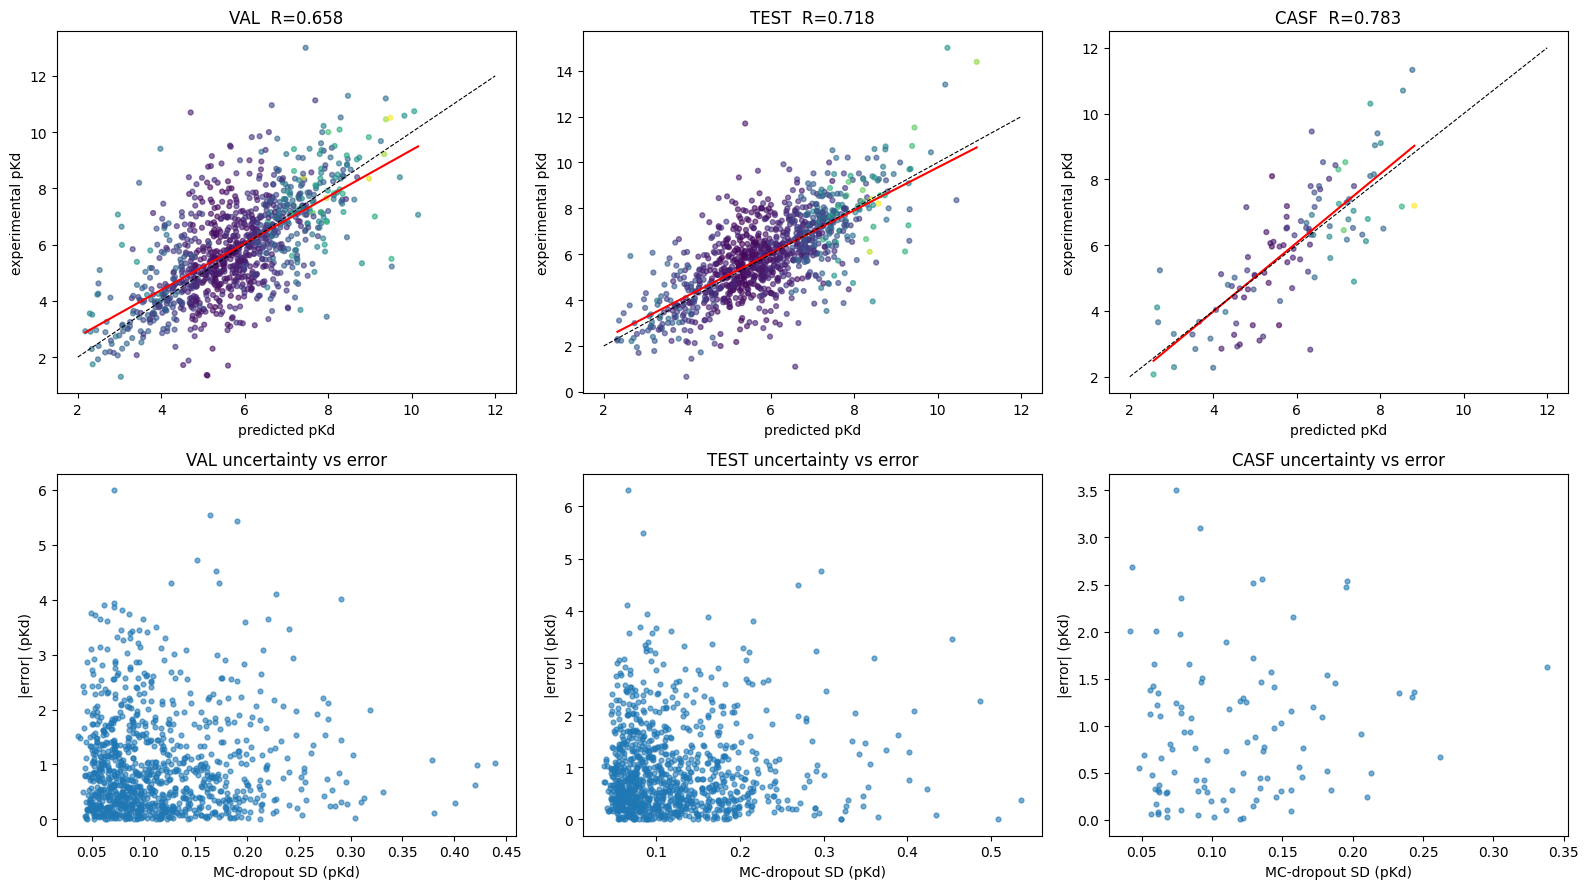

Saved to /content/drive/MyDrive/agentic_pla/outputs -> ['agentic_model.pt', 'agentic_results.png', 'metrics_all.csv', 'predictions_casf.csv', 'predictions_test.csv', 'predictions_val.csv']


In [11]:
#@title 11. Plots + save predictions, metrics and model weights
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for j, ds in enumerate(["val", "test", "casf"]):
    d_ = PRED[ds]; a, b = np.polyfit(d_.pred_pKd, d_.true_pKd, 1); xs = np.linspace(d_.pred_pKd.min(), d_.pred_pKd.max(), 50)
    r_ = pearsonr(d_.pred_pKd, d_.true_pKd)[0]
    ax[0, j].scatter(d_.pred_pKd, d_.true_pKd, s=12, alpha=.6, c=d_.uncertainty_pKd, cmap="viridis")
    ax[0, j].plot(xs, a * xs + b, "r-"); ax[0, j].plot([2, 12], [2, 12], "k--", lw=.8)
    ax[0, j].set_title(f"{ds.upper()}  R={r_:.3f}"); ax[0, j].set_xlabel("predicted pKd"); ax[0, j].set_ylabel("experimental pKd")
    ax[1, j].scatter(d_.uncertainty_pKd, d_.abs_error_pKd, s=12, alpha=.6)
    ax[1, j].set_xlabel("MC-dropout SD (pKd)"); ax[1, j].set_ylabel("|error| (pKd)"); ax[1, j].set_title(f"{ds.upper()} uncertainty vs error")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/agentic_results.png", dpi=150); plt.show()

for ds, d_ in PRED.items(): d_.to_csv(f"{RES_DIR}/predictions_{ds}.csv", index=False)
RES.to_csv(f"{RES_DIR}/metrics_all.csv", index=False)
torch.save(dict(models=[m.state_dict() for m in MODELS], hp=best_hp, generator=FULL_GEN.state_dict(),
                fold_generators=[m.state_dict() for m in FOLD_MODELS], norm=NORM, sig=(SIG_MU.cpu(), SIG_SD.cpu()),
                MU=MU, SD=SD, cfg=CFG), f"{RES_DIR}/agentic_model.pt")
print("Saved to", RES_DIR, "->", sorted(os.listdir(RES_DIR)))

In [12]:
#@title 12. Predict a NEW protein sequence + SMILES (pKd + MC-dropout uncertainty)
def predict_new(seq, smiles, verbose=True):
    """Structure lookup: exact sequence match in the database -> its stored 5 A pocket; otherwise the pocket of the
    most similar database protein (flagged as 'borrowed'). Retrieval DB = training partition."""
    seq = seq.strip().upper()
    pe = embed_proteins([seq]); le = embed_smiles([smiles]); free_encoders()
    P = tt((pe - NORM["PM"]) / NORM["PS"]); L = tt((le - NORM["LM"]) / NORM["LS"]); Pn = F.normalize(P, dim=-1)
    hit = np.where(df.protein_seq.values == seq)[0]
    if len(hit): r = hit[0]; src = f"exact match ({df.pdb_id.iloc[r]})"
    else:
        r = int((Pn @ T["Pn"].T).argmax()); src = f"BORROWED from most similar protein ({df.pdb_id.iloc[r]})"
    R = pocket_rep(RAW_K[r:r + 1], COMP[r:r + 1])
    with torch.no_grad():
        _, H = FULL_GEN(P, L); zb = torch.stack([m(P, L)[0] for m in FOLD_MODELS]).mean(0)
    T2 = {k: torch.cat([T[k], v]) for k, v in dict(P=P, Pn=Pn, L=L, Ln=F.normalize(L, dim=-1), R=R, H=H, Z=torch.zeros(1, device=dev)).items()}
    sp = build_split(T2, [N], DB_TRAIN, INDEX_TRAIN, torch.cat([ZBASE, zb]), False); sp["X"] = (sp["X"] - SIG_MU) / SIG_SD
    P_, A_ = zip(*[predict_mc(m, sp, CFG["mc_samples"], T2) for m in MODELS]); P_ = np.concatenate(P_, 0)
    out = dict(pKd=float(P_.mean() * SD + MU), uncertainty_SD=float(P_.std() * SD), pocket_source=src,
               neighbours=[df.pdb_id.iloc[int(i)] for i in sp["nbr"][0].cpu().numpy()], alpha=np.mean(A_, 0)[0].round(3).tolist())
    if verbose: print(out)
    return out

# Example (uses the first test complex; replace with your own sequence / SMILES)
_r = rows["test"][0]; _ = predict_new(df.protein_seq.iloc[_r], df.ligand_smiles.iloc[_r]); print("experimental pKd:", round(float(Y[_r]), 3))

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/81.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/361 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.68GB            

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/112 [00:00<?, ?it/s]

[transformers] T5EncoderModel LOAD REPORT from: laituan245/molt5-base
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'pKd': 8.339686393737793, 'uncertainty_SD': 0.29919689893722534, 'pocket_source': 'exact match (1a4k)', 'neighbours': ['4fab', '5alc', '5alb'], 'alpha': [0.3610000014305115, 0.33500000834465027, 0.30399999022483826]}
experimental pKd: 8.0


## Reviewer-revision cells (13-19) - run AFTER cells 1-12
Adds: (13) ligand-only / protein-only / no-retrieval / fixed-K=3,5,7 / uniform-weight baselines with identical split, hyper-parameters and seeds;
(14) per-seed mean±SD and 95% bootstrap CIs with paired tests; (15) seen/unseen and similarity-to-train stratified results;
(16) truncation frequency and its effect on error; (17) dataset report regenerated from the CSVs; (18) manuscript facts (shape trace, MC dropout, clamping, error sign, model revisions);
(19) comparison table restricted to comparable settings. Original cells 1-12 are unchanged. Error convention everywhere: **error = predicted - experimental**.
Cells 13 and 14 train extra models (K=5/7, uniform, baselines x n_seeds): expect roughly 1-2x the runtime of cell 9. Set `CFG["baseline_ks"]=[]` to skip K=5/7.

In [13]:
#@title 13. Baselines & fixed-K variants under the SAME split, hyper-parameters and seeds (reviewer pts 2, 7, 16)
# Everything below uses: the same train/val/test/CASF partitions, the same best_hp, the same early-stopping rule,
# and the same seed list as the main ensemble (MODELS, cell 9). K is fixed (no adaptive retrieval).
CFG.setdefault("baseline_ks", [5, 7])                         # extra fixed-K variants; K=3 is the main model
SEEDS = [CFG["seed"] + 100 * s for s in range(CFG["n_seeds"])]   # identical to the seeds used for MODELS in cell 9
EVAL_SETS = ["val", "test", "casf"]
to_pkd = lambda z: np.asarray(z) * SD + MU
MEMBER_PRED, RUNTIME = {}, {}        # variant -> {dataset: (n_members, n_rows) predictions in pKd}; variant -> train seconds

def fit_with_split(spl, hp, seed, uniform=False):
    global SPL
    old = SPL; SPL = spl                                      # fit_stage2 reads the global SPL
    try: return fit_stage2(hp, seed, uniform)[0]
    finally: SPL = old

def members_stage2(models, spl):
    return {ds: np.stack([to_pkd(predict_det(m, spl[ds]).cpu().numpy()) for m in models]) for ds in EVAL_SETS}

def build_spl_for_k(k):
    old = CFG["K"]; CFG["K"] = k
    try:
        spl = {"train": build_split(T, rows["train"], DB_TRAIN, INDEX_TRAIN, ZBASE, True),
               "val":   build_split(T, rows["val"],   DB_TRAIN, INDEX_TRAIN, ZBASE, False),
               "test":  build_split(T, rows["test"],  DB_TRAIN, INDEX_TRAIN, ZBASE, False)}
        if CFG["casf_db"] == "train+val":
            dbc = np.concatenate([rows["train"], rows["val"]])
            ixc = make_index(T["H"][torch.as_tensor(dbc, device=dev)].cpu().numpy())
        else: dbc, ixc = DB_TRAIN, INDEX_TRAIN
        spl["casf"] = build_split(T, rows["casf"], dbc, ixc, ZBASE, False)
    finally: CFG["K"] = old
    mu = spl["train"]["X"].reshape(-1, 5).mean(0); sd = spl["train"]["X"].reshape(-1, 5).std(0) + 1e-6
    for s in spl.values(): s["X"] = (s["X"] - mu) / sd         # signal standardisation with TRAIN statistics only
    return spl

class FeatMLP(nn.Module):
    def __init__(s, d, h=512, p=0.2):
        super().__init__()
        s.net = nn.Sequential(nn.Dropout(0.1), nn.LayerNorm(d), nn.Linear(d, h), nn.GELU(), nn.Dropout(p),
                              nn.Linear(h, 256), nn.GELU(), nn.Dropout(p), nn.Linear(256, 1))
    def forward(s, x): return s.net(x).squeeze(-1)

def train_feat_mlp(F_, seed, lr=1e-3, wd=1e-2, bs=256):
    set_seed(seed); m = FeatMLP(F_.shape[1]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    tr = torch.as_tensor(rows["train"], device=dev); va = torch.as_tensor(rows["val"], device=dev)
    best, bad, bsd = 1e9, 0, None
    for ep in range(CFG["max_epochs"]):
        m.train(); perm = tr[torch.randperm(len(tr), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; loss = F.mse_loss(m(F_[b]), T["Z"][b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad(): v = F.mse_loss(m(F_[va]), T["Z"][va]).sqrt().item()
        sch.step(v)
        if v < best - 1e-4: best, bad, bsd = v, 0, {k: x.clone() for k, x in m.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]: break
    m.load_state_dict(bsd); return m.eval()

def feat_members(F_):
    t0 = time.time(); out = {ds: [] for ds in EVAL_SETS}
    for s in SEEDS:
        m = train_feat_mlp(F_, s)
        with torch.no_grad():
            for ds in EVAL_SETS: out[ds].append(to_pkd(m(F_[torch.as_tensor(rows[ds], device=dev)]).cpu().numpy()))
    return {ds: np.stack(v) for ds, v in out.items()}, time.time() - t0

def stage1_members():
    t0 = time.time(); out = {ds: [] for ds in EVAL_SETS}
    for s in SEEDS:
        m, _ = train_gen(rows["train"], rows["val"], s)
        for ds in EVAL_SETS: out[ds].append(to_pkd(gen_forward(m, rows[ds])[0].cpu().numpy()))
    return {ds: np.stack(v) for ds, v in out.items()}, time.time() - t0

# ---- 1) main model (already trained in cell 9; same seeds) -------------------------------------------------
MEMBER_PRED["Agentic K=3 (main)"] = members_stage2(MODELS, SPL)
# ---- 2) no-retrieval / single-modality baselines ----------------------------------------------------------
MEMBER_PRED["No retrieval (stage-1 P+L regressor)"], RUNTIME["No retrieval (stage-1 P+L regressor)"] = stage1_members()
MEMBER_PRED["Ligand-only MLP (MolT5)"], RUNTIME["Ligand-only MLP (MolT5)"] = feat_members(T["L"])
MEMBER_PRED["Protein-only MLP (ProtBERT)"], RUNTIME["Protein-only MLP (ProtBERT)"] = feat_members(T["P"])
# ---- 3) fixed-K variants (K=3 reuses SPL; 5 and 7 are rebuilt from the TRAIN-only index) ---------------------
SPL_K = {3: SPL}
for k in CFG["baseline_ks"]:
    SPL_K[k] = build_spl_for_k(k)
    t0 = time.time(); models_k = [fit_with_split(SPL_K[k], best_hp, s) for s in SEEDS]
    RUNTIME[f"Agentic K={k}"] = time.time() - t0
    MEMBER_PRED[f"Agentic K={k}"] = members_stage2(models_k, SPL_K[k])
    print(f"K={k} trained ({RUNTIME[f'Agentic K={k}']:.0f}s)")
# ---- 4) uniform-weight ablation, all seeds (not only one member) --------------------------------------------
t0 = time.time(); uni_models = [fit_with_split(SPL, best_hp, s, uniform=True) for s in SEEDS]
RUNTIME["Agentic uniform weights K=3"] = time.time() - t0
MEMBER_PRED["Agentic uniform weights K=3"] = members_stage2(uni_models, SPL)
# ---- 5) training-free kNN baselines (uniform mean of the retrieved neighbours' labels) ---------------------
for k, spl in SPL_K.items():
    MEMBER_PRED[f"kNN uniform K={k}"] = {ds: to_pkd(T["Z"][spl[ds]["nbr"]].mean(1).cpu().numpy())[None] for ds in EVAL_SETS}

ORDER = [v for v in ["No retrieval (stage-1 P+L regressor)", "Ligand-only MLP (MolT5)", "Protein-only MLP (ProtBERT)",
                     "kNN uniform K=3", "kNN uniform K=5", "kNN uniform K=7", "Agentic uniform weights K=3",
                     "Agentic K=3 (main)", "Agentic K=5", "Agentic K=7"] if v in MEMBER_PRED]
np.savez_compressed(f"{RES_DIR}/member_predictions.npz",
                    **{f"{v}|{ds}": MEMBER_PRED[v][ds] for v in MEMBER_PRED for ds in EVAL_SETS})
print("Variants:", ORDER); print("Train time (s):", {k: round(v) for k, v in RUNTIME.items()})

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

K=5 trained (36s)
K=7 trained (29s)
Variants: ['No retrieval (stage-1 P+L regressor)', 'Ligand-only MLP (MolT5)', 'Protein-only MLP (ProtBERT)', 'kNN uniform K=3', 'kNN uniform K=5', 'kNN uniform K=7', 'Agentic uniform weights K=3', 'Agentic K=3 (main)', 'Agentic K=5', 'Agentic K=7']
Train time (s): {'No retrieval (stage-1 P+L regressor)': 21, 'Ligand-only MLP (MolT5)': 9, 'Protein-only MLP (ProtBERT)': 11, 'Agentic K=5': 36, 'Agentic K=7': 29, 'Agentic uniform weights K=3': 27}


In [14]:
#@title 14. Statistical robustness - per-seed mean ± SD, ensemble metrics with 95% bootstrap CIs, paired tests vs main model (pts 7, 16)
# Error convention used everywhere: error = predicted - experimental (positive = over-prediction).
B_BOOT = 2000
def boot_metrics(y, p, IDX):
    yb, pb = y[IDX], p[IDX]; e = pb - yb
    yc = yb - yb.mean(1, keepdims=True); pc = pb - pb.mean(1, keepdims=True)
    return dict(RMSE=np.sqrt((e ** 2).mean(1)), MAE=np.abs(e).mean(1),
                Pearson=(yc * pc).sum(1) / np.sqrt((yc ** 2).sum(1) * (pc ** 2).sum(1) + 1e-12),
                R2=1 - (e ** 2).sum(1) / ((yc ** 2).sum(1) + 1e-12))
ci95 = lambda x: np.percentile(x, [2.5, 97.5])
fmt_ci = lambda pt, x: f"{pt:.3f} [{ci95(x)[0]:.3f}, {ci95(x)[1]:.3f}]"
MAIN = "Agentic K=3 (main)"

def summarise(ds, order=None):
    order = order or ORDER; y = Y[rows[ds]].astype(np.float64); n = len(y)
    IDX = np.random.RandomState(CFG["seed"]).randint(0, n, (B_BOOT, n))        # SAME resamples for every variant -> paired
    bm_main = boot_metrics(y, MEMBER_PRED[MAIN][ds].mean(0), IDX); out = []
    for v in order:
        P = MEMBER_PRED[v][ds].astype(np.float64); pe = P.mean(0); pt = _metrics(y, pe); bm = boot_metrics(y, pe, IDX)
        per = pd.DataFrame([_metrics(y, p) for p in P]); sdv = lambda c: per[c].std(ddof=1) if len(per) > 1 else float("nan")
        r = {"variant": v, "members": len(P),
             "RMSE per-seed (mean±SD)": f"{per.RMSE.mean():.3f}±{sdv('RMSE'):.3f}",
             "Pearson per-seed (mean±SD)": f"{per.Pearson.mean():.3f}±{sdv('Pearson'):.3f}",
             "RMSE ensemble [95% CI]": fmt_ci(pt["RMSE"], bm["RMSE"]), "MAE ensemble [95% CI]": fmt_ci(pt["MAE"], bm["MAE"]),
             "Pearson ensemble [95% CI]": fmt_ci(pt["Pearson"], bm["Pearson"]), "R2 ensemble": round(pt["R2"], 3)}
        if v != MAIN:
            d = bm["RMSE"] - bm_main["RMSE"]                                    # >0 : variant worse than main
            r["dRMSE vs main [95% CI]"] = f"{d.mean():+.3f} [{ci95(d)[0]:+.3f}, {ci95(d)[1]:+.3f}]"
            r["P(main not better)"] = round(float((d <= 0).mean()), 4)          # one-sided paired-bootstrap p-value
        out.append(r)
    return pd.DataFrame(out)

pd.set_option("display.width", 250, "display.max_columns", 30, "display.max_colwidth", 40)
STATS = {}
for ds in ["val", "test", "casf"]:
    STATS[ds] = summarise(ds)
    print(f"\n=========== {ds.upper()}  (n={len(rows[ds])}{', CASF-2016 Kd subset' if ds == 'casf' else ''})  95% bootstrap CI, B={B_BOOT} ===========")
    print(STATS[ds].to_string(index=False))
    STATS[ds].to_csv(f"{RES_DIR}/stats_{ds}.csv", index=False)

# Fair-comparison reminder: 'per-seed' rows are single-model numbers (compare these against single-model baselines);
# 'ensemble' rows average the SAME number of members (n_seeds) for every trainable variant.
# Headline numbers of cell 10 use MC-dropout means (M=10 per member); here members are scored deterministically (dropout off).
_zm = ensemble_predict(MODELS, SPL["test"])[0] * SD + MU
print("\nTest RMSE: deterministic ensemble = %.4f | MC-dropout ensemble (cell 10) = %.4f"
      % (math.sqrt(np.mean((MEMBER_PRED[MAIN]["test"].mean(0) - Y[rows["test"]]) ** 2)), math.sqrt(np.mean((_zm - Y[rows["test"]]) ** 2))))


=========== VAL  (n=1005)  95% bootstrap CI, B=2000 ===========
                             variant  members RMSE per-seed (mean±SD) Pearson per-seed (mean±SD) RMSE ensemble [95% CI] MAE ensemble [95% CI] Pearson ensemble [95% CI]  R2 ensemble  dRMSE vs main [95% CI]  P(main not better)
No retrieval (stage-1 P+L regressor)        5             1.327±0.015                0.669±0.009   1.282 [1.209, 1.358]  0.941 [0.889, 0.996]      0.689 [0.649, 0.727]        0.465 -0.062 [-0.088, -0.037]              1.0000
             Ligand-only MLP (MolT5)        5             1.475±0.011                0.553±0.010   1.445 [1.376, 1.520]  1.113 [1.058, 1.172]      0.571 [0.524, 0.617]        0.320 +0.101 [+0.038, +0.166]              0.0000
         Protein-only MLP (ProtBERT)        5             1.531±0.006                0.522±0.008   1.509 [1.415, 1.610]  1.135 [1.077, 1.196]      0.534 [0.473, 0.588]        0.259 +0.165 [+0.084, +0.253]              0.0000
                     kNN uniform K=

In [15]:
#@title 15. Leakage / novelty evidence - seen vs unseen protein & ligand, and similarity-to-train bins (pts 2, 3)
tr_prot = set(df.protein_seq.values[rows["train"]]); tr_lig = set(df.ligand_smiles.values[rows["train"]])

@torch.no_grad()
def max_sim_to_train(Mat, q):
    trt = torch.as_tensor(rows["train"], device=dev); qi = torch.as_tensor(q, device=dev); out = []
    for i in range(0, len(qi), 512): out.append((Mat[qi[i:i + 512]] @ Mat[trt].T).max(1).values)
    return torch.cat(out).cpu().numpy()

def strata(ds):
    r = rows[ds]
    ps = np.array([s in tr_prot for s in df.protein_seq.values[r]]); ls = np.array([s in tr_lig for s in df.ligand_smiles.values[r]])
    S = {"ALL": np.ones(len(r), bool), "protein seen in train": ps, "protein UNSEEN": ~ps,
         "ligand seen in train": ls, "ligand UNSEEN": ~ls, "protein AND ligand unseen (cold pair)": ~ps & ~ls}
    for nm, Mat in [("protein", T["Pn"]), ("ligand", T["Ln"])]:                       # thirds of max cosine similarity to train
        sim = max_sim_to_train(Mat, r); b = pd.qcut(pd.Series(sim).rank(method="first"), 3, labels=["low", "mid", "high"]).values
        for lv in ["low", "mid", "high"]: S[f"{nm}-sim {lv} third"] = (b == lv)
    return S

STRAT_VARIANTS = [v for v in ["No retrieval (stage-1 P+L regressor)", "Ligand-only MLP (MolT5)", "kNN uniform K=3", MAIN] if v in MEMBER_PRED]
BASE = "No retrieval (stage-1 P+L regressor)"
rngS = np.random.RandomState(CFG["seed"]); STRAT = {}
for ds in ["test", "casf"]:
    y = Y[rows[ds]].astype(np.float64); S = strata(ds); P = {v: MEMBER_PRED[v][ds].mean(0).astype(np.float64) for v in STRAT_VARIANTS}; out = []
    for nm, mask in S.items():
        m = int(mask.sum())
        if m < 10: continue
        IDX = rngS.randint(0, m, (1000, m)); yy = y[mask]; rec = {"stratum": nm, "n": m, "% of set": round(100 * m / len(y), 1)}
        bms = {v: boot_metrics(yy, P[v][mask], IDX) for v in STRAT_VARIANTS}
        for v in STRAT_VARIANTS: rec[f"RMSE {v.split(' (')[0]}"] = fmt_ci(math.sqrt(np.mean((P[v][mask] - yy) ** 2)), bms[v]["RMSE"])
        rec["Pearson main"] = fmt_ci(float(np.corrcoef(P[MAIN][mask], yy)[0, 1]), bms[MAIN]["Pearson"])
        if BASE in P: d = bms[BASE]["RMSE"] - bms[MAIN]["RMSE"]; rec["RMSE gain vs no-retrieval [95% CI]"] = f"{d.mean():+.3f} [{ci95(d)[0]:+.3f}, {ci95(d)[1]:+.3f}]"
        out.append(rec)
    STRAT[ds] = pd.DataFrame(out)
    print(f"\n=========== {ds.upper()} stratified by novelty w.r.t. TRAIN (error = pred - exp) ===========")
    print(STRAT[ds].to_string(index=False)); STRAT[ds].to_csv(f"{RES_DIR}/stratified_{ds}.csv", index=False)
print("\nSeen/unseen is by EXACT sequence / canonical SMILES match; similarity thirds use cosine of standardised ProtBERT / MolT5 embeddings.")


=========== TEST stratified by novelty w.r.t. TRAIN (error = pred - exp) ===========
                              stratum    n  % of set    RMSE No retrieval RMSE Ligand-only MLP RMSE kNN uniform K=3     RMSE Agentic K=3         Pearson main RMSE gain vs no-retrieval [95% CI]
                                  ALL 1005     100.0 1.212 [1.143, 1.277] 1.394 [1.323, 1.461] 1.395 [1.316, 1.478] 1.265 [1.194, 1.342] 0.718 [0.681, 0.752]            -0.053 [-0.086, -0.021]
                protein seen in train  393      39.1 1.076 [0.962, 1.194] 1.343 [1.242, 1.443] 1.203 [1.064, 1.346] 1.110 [0.989, 1.238] 0.806 [0.752, 0.846]            -0.034 [-0.072, +0.003]
                       protein UNSEEN  612      60.9 1.292 [1.206, 1.372] 1.425 [1.334, 1.508] 1.505 [1.397, 1.596] 1.356 [1.262, 1.440] 0.652 [0.600, 0.705]            -0.064 [-0.109, -0.023]
                 ligand seen in train  270      26.9 1.251 [1.116, 1.397] 1.423 [1.262, 1.582] 1.388 [1.233, 1.555] 1.312 [1.169, 1.468] 0.703

In [16]:
#@title 16. Truncation analysis at the limits ACTUALLY used (1024 / 256 / 128) and at the legacy limits (512 / 128), plus effect on error (pt 8)
from transformers import AutoTokenizer
from scipy.stats import mannwhitneyu
_tokm = AutoTokenizer.from_pretrained(CFG["mol_model"])
_uni = df.ligand_smiles.astype(str).unique()
_len = dict(zip(_uni, [len(x) for x in _tokm(list(_uni))["input_ids"]]))           # MolT5 tokens incl. </s>
df["smi_tok_len"] = df.ligand_smiles.astype(str).map(_len).values
df["prot_len"] = df.protein_seq.astype(str).str.len().values                        # ProtBERT: one token per residue
df["pocket_len"] = df.pocket_seq.astype(str).str.len().values
# encode_texts uses max_length = max_len + 2 for the tokenizer (special tokens included) and cuts proteins at max_prot_len residues
df["trunc_prot"] = df.prot_len > CFG["max_prot_len"]
df["trunc_smi"] = df.smi_tok_len > CFG["max_smiles_len"] + 2
df["trunc_pocket"] = df.pocket_len > CFG["max_pocket_len"]
df["trunc_prot_512"] = df.prot_len > 512; df["trunc_smi_128"] = df.smi_tok_len > 128 + 2

rowsT = []
for p in ["train", "val", "test", "casf"]:
    d_ = df[df.part == p]
    rowsT.append({"partition": p, "n": len(d_),
                  f"% protein > {CFG['max_prot_len']} (used)": round(100 * d_.trunc_prot.mean(), 2),
                  f"% SMILES > {CFG['max_smiles_len']} tok (used)": round(100 * d_.trunc_smi.mean(), 2),
                  f"% pocket > {CFG['max_pocket_len']}": round(100 * d_.trunc_pocket.mean(), 2),
                  "% protein > 512 (legacy)": round(100 * d_.trunc_prot_512.mean(), 2), "% SMILES > 128 tok (legacy)": round(100 * d_.trunc_smi_128.mean(), 2)})
TRUNC_FREQ = pd.DataFrame(rowsT); print(TRUNC_FREQ.to_string(index=False))
allp = df[df.part != "casf"]
print("\nProtein length quantiles (PDBbind):", allp.prot_len.quantile([.5, .9, .95, .99]).round(0).to_dict(), "| max", int(allp.prot_len.max()))
print("SMILES token length quantiles (PDBbind):", allp.smi_tok_len.quantile([.5, .9, .95, .99]).round(0).to_dict(), "| max", int(allp.smi_tok_len.max()))
TRUNC_FREQ.to_csv(f"{RES_DIR}/truncation_frequency.csv", index=False)

# effect on prediction error (main ensemble, pred - exp)
rowsE = []
for ds in ["val", "test", "casf"]:
    r = rows[ds]; e = MEMBER_PRED[MAIN][ds].mean(0) - Y[r]
    for flag, lab in [("trunc_prot", f"protein > {CFG['max_prot_len']}"), ("trunc_smi", f"SMILES > {CFG['max_smiles_len']} tok"),
                      ("trunc_prot_512", "protein > 512 (legacy)"), ("trunc_smi_128", "SMILES > 128 tok (legacy)")]:
        f = df[flag].values[r]
        pv = round(float(mannwhitneyu(np.abs(e[f]), np.abs(e[~f]))[1]), 4) if (f.sum() >= 5 and (~f).sum() >= 5) else float("nan")
        for g, gl in [(True, "truncated"), (False, "not truncated")]:
            if (f == g).sum() >= 5: rowsE.append({"dataset": ds, "criterion": lab, "group": gl, "n": int((f == g).sum()),
                                                  "RMSE": round(float(np.sqrt(np.mean(e[f == g] ** 2))), 3), "MAE": round(float(np.abs(e[f == g]).mean()), 3),
                                                  "mean signed err": round(float(e[f == g].mean()), 3), "MWU p (|err| trunc vs not)": pv})
TRUNC_EFFECT = pd.DataFrame(rowsE); print("\n", TRUNC_EFFECT.to_string(index=False)); TRUNC_EFFECT.to_csv(f"{RES_DIR}/truncation_effect.csv", index=False)

partition    n  % protein > 1024 (used)  % SMILES > 256 tok (used)  % pocket > 128  % protein > 512 (legacy)  % SMILES > 128 tok (legacy)
    train 4690                      0.6                       4.69             0.0                      9.17                        24.07
      val 1005                      0.1                       5.07             0.0                      7.76                        26.27
     test 1005                      0.7                       3.78             0.0                      9.75                        21.59
     casf  107                      0.0                       0.00             0.0                     12.15                         0.93

Protein length quantiles (PDBbind): {0.5: 257.0, 0.9: 496.0, 0.95: 639.0, 0.99: 907.0} | max 2701
SMILES token length quantiles (PDBbind): {0.5: 64.0, 0.9: 213.0, 0.95: 254.0, 0.99: 336.0} | max 499

 dataset                 criterion         group    n  RMSE   MAE  mean signed err  MWU p (|err| trunc vs not

In [17]:
#@title 17. Regenerated dataset report computed from the CSVs actually used (pts 1, 2, 8, 11) - replaces the inconsistent preprocessing_report.json
def desc(a):
    a = np.asarray(a, np.float64); return dict(n=int(len(a)), min=float(a.min()), median=float(np.median(a)), max=float(a.max()), mean=float(a.mean()), sd=float(a.std(ddof=1)) if len(a) > 1 else 0.0)

P_ = df[df.part != "casf"]; C_ = df[df.part == "casf"]; TRN = df[df.part == "train"]; TST = df[df.part == "test"]
trp, trl = set(TRN.protein_seq), set(TRN.ligand_smiles)
raw_col = "ligand_smiles_raw" if "ligand_smiles_raw" in df.columns else "ligand_smiles"
trp_pairs = set(zip(TRN.protein_seq, TRN.ligand_smiles))
REPORT = {
  "NOTE": "Counts marked [from original preprocessing log] cannot be recomputed from the CSVs and are copied from preprocessing_report.json.",
  "config": {"seed": 42, "split_mode": "random", "chain_policy": "contact_unique", "pocket_cutoff_A": 5.0, "min_protein_len": 50,
             "model_max_prot_len": CFG["max_prot_len"], "model_max_smiles_len": CFG["max_smiles_len"], "model_max_pocket_len": CFG["max_pocket_len"]},
  "label_handling [from original preprocessing log]": {"not_kd_rejected": 11994, "kd_censored_or_approximate_rejected": 108,
        "duplicate_pairs_removed": 97, "protein_too_short_dropped": 30, "ligand_rdkit_failed": 1, "casf_excluded_from_pdbbind": 285},
  "pdbbind": {
     "n_complexes": int(len(P_)), "n_per_split": {k: int((P_.part == k).sum()) for k in ["train", "val", "test"]},
     "unique_proteins_raw": int(P_.protein_seq.nunique()), "unique_proteins_after_truncation": int(P_.protein_seq.str[:CFG["max_prot_len"]].nunique()),
     "unique_ligands_raw_smiles": int(P_[raw_col].nunique()), "unique_ligands_canonical_smiles": int(P_.ligand_smiles.nunique()),
     "unique_pdb_ids": int(P_.pdb_id.nunique()), "unique_protein_ligand_pairs": int(len(set(zip(P_.protein_seq, P_.ligand_smiles)))),
     "complexes_per_protein": desc(P_.protein_seq.value_counts().values),
     "pKd_by_split": {k: desc(P_[P_.part == k].binding_affinity) for k in ["train", "val", "test"]},
     "protein_length": desc(P_.prot_len), "smiles_token_length": desc(P_.smi_tok_len), "pocket_n_residues": desc(P_.pocket_len),
     "frac_pocket_ok": float(P_.pocket_ok.astype(bool).mean()) if "pocket_ok" in P_ else None,
     "frac_pockets_le_5_residues": float((P_.pocket_len <= 5).mean()),
     "truncation_at_model_limits": {"protein": float(P_.trunc_prot.mean()), "smiles": float(P_.trunc_smi.mean()), "pocket": float(P_.trunc_pocket.mean())},
     "truncation_at_legacy_limits_512_128": {"protein": float(P_.trunc_prot_512.mean()), "smiles": float(P_.trunc_smi_128.mean())},
     "frac_complexes_with_X_in_protein": float(P_.protein_seq.str.contains("X").mean()),
     "overlap_train_test": {"proteins_in_both": len(trp & set(TST.protein_seq)), "ligands_in_both": len(trl & set(TST.ligand_smiles)),
        "protein_ligand_pairs_in_both": len(trp_pairs & set(zip(TST.protein_seq, TST.ligand_smiles))),
        "frac_test_complexes_protein_seen": float(TST.protein_seq.isin(trp).mean()), "frac_test_complexes_ligand_seen": float(TST.ligand_smiles.isin(trl).mean()),
        "frac_test_complexes_both_unseen": float((~TST.protein_seq.isin(trp) & ~TST.ligand_smiles.isin(trl)).mean())}},
  "casf2016_kd_subset": {
     "n_complexes": int(len(C_)), "label": "Kd-only subset of the 285-complex CASF-2016 core set; NOT the full benchmark",
     "drops [from original preprocessing log - verify]": {"no_usable_kd_label": 178, "logged_as_missing_files": 107,
        "WARNING": "the original JSON reported casf2016.n_complexes=0 while the CSV has %d rows; the 'missing_files' counter equals the retained count and is probably mislabelled" % len(C_)},
     "pdb_id_overlap_with_pdbbind": int(len(set(C_.pdb_id) & set(P_.pdb_id))),
     "unique_proteins": int(C_.protein_seq.nunique()), "unique_ligands": int(C_.ligand_smiles.nunique()),
     "frac_protein_seq_exact_in_train": float(C_.protein_seq.isin(trp).mean()), "frac_ligand_smiles_exact_in_train": float(C_.ligand_smiles.isin(trl).mean()),
     "frac_both_unseen": float((~C_.protein_seq.isin(trp) & ~C_.ligand_smiles.isin(trl)).mean()),
     "pKd": desc(C_.binding_affinity), "protein_length": desc(C_.prot_len), "pocket_n_residues": desc(C_.pocket_len),
     "truncation_at_model_limits": {"protein": float(C_.trunc_prot.mean()), "smiles": float(C_.trunc_smi.mean())}},
}
json.dump(REPORT, open(f"{RES_DIR}/dataset_report_regenerated.json", "w"), indent=2, default=float)
print(json.dumps(REPORT, indent=1, default=float)[:6000])

{
 "NOTE": "Counts marked [from original preprocessing log] cannot be recomputed from the CSVs and are copied from preprocessing_report.json.",
 "config": {
  "seed": 42,
  "split_mode": "random",
  "chain_policy": "contact_unique",
  "pocket_cutoff_A": 5.0,
  "min_protein_len": 50,
  "model_max_prot_len": 1024,
  "model_max_smiles_len": 256,
  "model_max_pocket_len": 128
 },
 "label_handling [from original preprocessing log]": {
  "not_kd_rejected": 11994,
  "kd_censored_or_approximate_rejected": 108,
  "duplicate_pairs_removed": 97,
  "protein_too_short_dropped": 30,
  "ligand_rdkit_failed": 1,
  "casf_excluded_from_pdbbind": 285
 },
 "pdbbind": {
  "n_complexes": 6700,
  "n_per_split": {
   "train": 4690,
   "val": 1005,
   "test": 1005
  },
  "unique_proteins_raw": 4667,
  "unique_proteins_after_truncation": 4667,
  "unique_ligands_raw_smiles": 5253,
  "unique_ligands_canonical_smiles": 5218,
  "unique_pdb_ids": 6700,
  "unique_protein_ligand_pairs": 6700,
  "complexes_per_protein"

In [18]:
#@title 18. Paper-code consistency - auto-generated facts for the manuscript (dimension trace, MC dropout, clamping, error sign, revisions) (pts 9, 12, 13, 14, 18)
# ---- (a) fusion tensor-shape trace on a real batch ------------------------------------------------------
_m = MODELS[0].eval(); _shapes = {}
def _hook(name):
    def f(mod, inp, out): _shapes[name] = tuple((out[0] if isinstance(out, tuple) else out).shape)
    return f
_hs = [getattr(_m, n).register_forward_hook(_hook(n)) for n in ["eh", "ep", "el", "ek", "ey", "ex", "ev_mix", "scorer", "q_proj", "attn", "n1", "ffn", "n2", "head"]]
with torch.no_grad(): _b = gather(T, SPL["test"], torch.arange(4, device=dev)); _u, _base, _al = _m.encode(_b); _out = _m.head_out(_u, _base)
for h in _hs: h.remove()
print("Shape trace (batch=4, K=%d, d=%d):" % (CFG["K"], best_hp["d"])); [print(f"  {k:8s} -> {v}") for k, v in _shapes.items()]
print("  alpha", tuple(_al.shape), "| flattened token output", tuple(_u.shape), "| prediction", tuple(_out.shape))

# ---- (b) clamping / NaN handling: the code applies NEITHER; check that it would have been a no-op ---------
_allz = np.concatenate([(MEMBER_PRED[MAIN][ds].mean(0) - MU) / SD for ds in EVAL_SETS])
CLAMP = dict(n_nan=int(np.isnan(_allz).sum()), frac_z_outside_pm5=float((np.abs(_allz) > 5).mean()))
print("\nClamping check (no clamping or nan_to_num is applied in this code):", CLAMP)

# ---- (c) consistent signed error, saved with the predictions -------------------------------------------
for ds, d_ in PRED.items():
    d_["signed_error_pKd"] = d_.pred_pKd - d_.true_pKd                       # pred - exp : positive = over-prediction
    d_.to_csv(f"{RES_DIR}/predictions_{ds}.csv", index=False)
print("Error convention: error = predicted - experimental (positive = over-prediction). Saved as signed_error_pKd.")

# ---- (d) model revisions (record what was actually resolved at run time) ---------------------------------
REV = {}
try:
    from huggingface_hub import HfApi
    for nm in [CFG["prot_model"], CFG["mol_model"]]: REV[nm] = HfApi().model_info(nm).sha
except Exception as e: REV = {"error": str(e)}
print("\nHub revisions (current head at run time; pass revision=<sha> to from_pretrained to pin them):", REV)

# ---- (e) text block to paste into the Methods section -----------------------------------------------------
n_par = sum(p.numel() for p in MODELS[0].parameters())
FACTS = f"""# Facts generated from the code (use these numbers in the manuscript)
- Data: PDBbind v2020 Kd-only, {len(P_)} complexes (train/val/test = {', '.join(str((P_.part==k).sum()) for k in ['train','val','test'])}); external: CASF-2016 Kd subset, n={len(C_)} (NOT the 285-complex benchmark).
- Encoders: {CFG['prot_model']} (rev {REV.get(CFG['prot_model'], 'n/a')}, fp16 on GPU) and {CFG['mol_model']} (T5 encoder, fp32, rev {REV.get(CFG['mol_model'], 'n/a')}).
  Pooling: mean over last hidden state, attention-mask and ALL special tokens excluded; then per-dimension standardisation with TRAIN mean/SD; cosine geometry uses L2-normalised vectors.
- Limits: protein {CFG['max_prot_len']} residues, SMILES {CFG['max_smiles_len']} tokens, pocket {CFG['max_pocket_len']} residues. Truncated (all complexes): protein {100*df.trunc_prot.mean():.2f}%, SMILES {100*df.trunc_smi.mean():.2f}%.
- Pocket: residues within {REPORT['config']['pocket_cutoff_A']} A of the bound ligand (chain policy {REPORT['config']['chain_policy']}); pockets are taken from the co-crystal structure of each query complex, i.e. the setting is structure-informed, not sequence-only.
- Retrieval: exact cosine (FAISS IndexFlatIP) over frozen stage-1 interaction embeddings; index built ONCE from the training partition; fixed K={CFG['K']} (adaptive retrieval removed after ablation). Train queries exclude their own row.
- Evidence signals (5): interaction, protein, ligand, pocket cosine similarities + label-free affinity-consistency (OOF base estimate). Scorer: Linear(5,32)-GELU-Linear(32,1) -> softmax over K.
- Fusion: d={best_hp['d']}; token sequence = [Q (query interaction+pocket), E_r (alpha-weighted evidence)] -> 2 tokens x d; 4-head self-attention (Q=K=V=token matrix, no cross-attention);
  residual+LayerNorm, FFN(d->2d->d), residual+LayerNorm, flatten (2d) -> Linear(2d,d)-GELU-Dropout(p={best_hp['p']})-Linear(d,1) plus learnable beta * (alpha-weighted neighbour z-affinity). {n_par:,} parameters per member.
- Training: AdamW (lr={best_hp['lr']}, wd={best_hp['wd']}, bs={best_hp['bs']}), MSE on z-scored pKd, ReduceLROnPlateau, early stopping on VALIDATION RMSE (patience {CFG['patience']}, max {CFG['max_epochs']} epochs), best-val checkpoint; test/CASF never used for selection. Hyper-parameters chosen on val only ({CFG['n_trials']} random trials).
- Ensemble: {CFG['n_seeds']} members (seeds {SEEDS}). MC dropout: M={CFG['mc_samples']} passes per member, ONLY the prediction-head dropout layer is stochastic (attention/input dropout off); reported prediction = mean of {CFG['n_seeds']*CFG['mc_samples']} draws, uncertainty = their SD (includes between-member spread).
- Numerical handling: no output clamping, no nan_to_num. Check: NaNs={CLAMP['n_nan']}, fraction of |z|>5 = {CLAMP['frac_z_outside_pm5']:.4f}.
- Error definition: error = predicted - experimental; positive = over-prediction. MAE/RMSE use absolute/squared error. SD = CASF-style residual SD of the linear fit y ~ a*p+b.
- Statistics: 95% percentile bootstrap over test complexes (B={B_BOOT}), paired resamples across variants; per-seed mean±SD over {CFG['n_seeds']} seeds.
"""
open(f"{RES_DIR}/paper_facts.md", "w").write(FACTS); print("\n" + FACTS)

Shape trace (batch=4, K=3, d=256):
  scorer   -> (4, 3, 1)
  eh       -> (4, 3, 256)
  ep       -> (4, 3, 256)
  el       -> (4, 3, 256)
  ek       -> (4, 3, 256)
  ey       -> (4, 3, 256)
  ex       -> (4, 3, 256)
  ev_mix   -> (4, 3, 256)
  q_proj   -> (4, 256)
  attn     -> (4, 2, 256)
  n1       -> (4, 2, 256)
  ffn      -> (4, 2, 256)
  n2       -> (4, 2, 256)
  head     -> (4, 1)
  alpha (4, 3) | flattened token output (4, 512) | prediction (4,)

Clamping check (no clamping or nan_to_num is applied in this code): {'n_nan': 0, 'frac_z_outside_pm5': 0.0}
Error convention: error = predicted - experimental (positive = over-prediction). Saved as signed_error_pKd.

Hub revisions (current head at run time; pass revision=<sha> to from_pretrained to pin them): {'Rostlab/prot_bert': '7a894481acdc12202f0a415dd567f6cfdb698908', 'laituan245/molt5-base': '7f2da6b30fd8ddc55b7867d53ce75e09bb85f284'}

# Facts generated from the code (use these numbers in the manuscript)
- Data: PDBbind v2020 Kd-o

In [19]:
#@title 19. Comparison table restricted to comparable settings (pt 19)
# Rows computed here (same processed data, same split, same seeds) are marked comparable = "yes".
# Literature rows are NOT filled in automatically: add them to LIT with their own training set / test set / label, and set
# comparable="no" unless the SAME training data, test set (the full 285 CASF-2016 core set vs our 107-complex Kd subset), label (Kd only vs Kd/Ki/IC50) and split were used.
LIT = [
    # dict(method="<name>", train_data="<...>", test_set="<...>", n_test=<int>, label="<Kd | Kd/Ki | ...>", split="<...>", comparable="no",
    #      RMSE=<float or None>, Pearson=<float or None>, MAE=<float or None>, SD=<float or None>, source="<citation key>"),
]
def own_row(v, ds, test_name):
    y = Y[rows[ds]].astype(np.float64); pe = MEMBER_PRED[v][ds].mean(0).astype(np.float64); m = _metrics(y, pe)
    return dict(method=v + (" [ensemble]" if len(MEMBER_PRED[v][ds]) > 1 else ""), train_data=f"PDBbind v2020 Kd-only train partition (n={len(rows['train'])})",
                test_set=test_name, n_test=len(y), label="pKd (Kd only)", split="random 70/15/15 (seed 42)" if ds == "test" else "external",
                comparable="yes (re-run, identical pipeline)", RMSE=round(m["RMSE"], 3), Pearson=round(m["Pearson"], 3), MAE=round(m["MAE"], 3), SD=round(m["SD"], 3), source="this work")
OWN = [own_row(v, "test", f"PDBbind held-out test (n={len(rows['test'])})") for v in ORDER] + \
      [own_row(v, "casf", f"CASF-2016 Kd subset (n={len(rows['casf'])} of 285)") for v in ORDER]
CMP = pd.DataFrame(OWN + LIT)
print(CMP.to_string(index=False)); CMP.to_csv(f"{RES_DIR}/comparison_table.csv", index=False)
try: open(f"{RES_DIR}/comparison_table.tex", "w").write(CMP.to_latex(index=False, na_rep="--", float_format="%.3f"))
except Exception as e: print("LaTeX export skipped:", e)
print("\nSuggested table footnote:\n"
      f"'Our CASF-2016 results are on the Kd-only subset (n={len(rows['casf'])} of 285 core-set complexes) with a model trained on {len(rows['train'])} PDBbind v2020 Kd-only complexes; "
      "published numbers on the full 285-complex set, with different training sets or label definitions, are not directly comparable and are shown for context only.'")

                                         method                                     train_data                           test_set  n_test         label                     split                       comparable  RMSE  Pearson   MAE    SD    source
No retrieval (stage-1 P+L regressor) [ensemble] PDBbind v2020 Kd-only train partition (n=4690)     PDBbind held-out test (n=1005)    1005 pKd (Kd only) random 70/15/15 (seed 42) yes (re-run, identical pipeline) 1.212    0.744 0.901 1.211 this work
             Ligand-only MLP (MolT5) [ensemble] PDBbind v2020 Kd-only train partition (n=4690)     PDBbind held-out test (n=1005)    1005 pKd (Kd only) random 70/15/15 (seed 42) yes (re-run, identical pipeline) 1.394    0.640 1.084 1.393 this work
         Protein-only MLP (ProtBERT) [ensemble] PDBbind v2020 Kd-only train partition (n=4690)     PDBbind held-out test (n=1005)    1005 pKd (Kd only) random 70/15/15 (seed 42) yes (re-run, identical pipeline) 1.474    0.584 1.090 1.471 this work
        